# Chapter 21 Companion Notebook: Case Studies and Capstone Projects

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wulinsuo/AI-in-Finance/blob/main/notebooks/chapter21.ipynb)

This notebook reproduces Chapter 21's end-to-end case study on the UCI/Kaggle "Default of Credit Card Clients" dataset (Yeh and Lien, 2009), downloading the real dataset directly from the UCI Machine Learning Repository, including an isotonic recalibration of the plain logistic regression (Section 6b) that fixes its lowest-decile miscalibration without retraining or discarding the model.

---

**© 2026 Wulin Suo. All rights reserved, except as the repository's [LICENSE](https://github.com/wulinsuo/AI-in-Finance/blob/main/LICENSE) allows:** you may view this notebook, download a copy for your own personal study, and run it on your own computer for that purpose. Any other reproduction, distribution, or derivative use needs the author's prior written permission (including use in teaching). Contact: Wulin.Suo@Queensu.ca

In [1]:
# Setup for Google Colab. Run locally, this cell does nothing: install the pinned
# packages once instead, with  python -m pip install -r requirements.txt
import sys
if "google.colab" in sys.modules:
    import subprocess, urllib.request
    _req_url = "https://raw.githubusercontent.com/wulinsuo/AI-in-Finance/main/requirements.txt"
    _reqs = [_line.split("#")[0].strip() for _line in urllib.request.urlopen(_req_url).read().decode().splitlines()]
    _reqs = [_r for _r in _reqs if _r and _r.split("==")[0] not in ("nbformat", "nbclient", "ipykernel")]
    if subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_reqs]).returncode == 0:
        print("Installed the package versions in requirements.txt. If Colab asks you to restart "
              "the session, restart it and run the notebook again from the top.")
    else:
        print("Could not install the pinned versions; continuing with Colab's own packages, "
              "so a few printed numbers may differ in the last digits from the book.")

In [2]:
# Check that the packages this chapter needs are installed, and show their versions
import importlib, sys
print(f"{'python':<12} {sys.version.split()[0]}")
_missing = []
for _pkg in ("numpy", "pandas", "sklearn", "xgboost", "shap", "xlrd", "matplotlib"):
    try:
        print(f"{_pkg:<12} {importlib.import_module(_pkg).__version__}")
    except ImportError:
        _missing.append(_pkg)
if _missing:
    raise ImportError(f"Missing package(s): {', '.join(_missing)}. Install the versions pinned in "
                      "requirements.txt with:  python -m pip install -r requirements.txt")

python       3.14.6
numpy        2.4.6


pandas       3.0.3


sklearn      1.9.0
xgboost      3.4.1


shap         0.53.0
xlrd         2.0.2
matplotlib   3.11.0


## 1. Download and load the raw dataset

Reproduces Section 21.1.1: the raw UCI file (30,000 accounts, 25 columns after the rename) and the summary statistics of Table 21.1. Look at the 22.12% default rate, far above a typical card portfolio, and at the raw file's `PAY_0` column, which the notebook renames to `PAY_1`.

In [3]:
import os
import urllib.request
import numpy as np
import pandas as pd

DATA_URL = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
DATA_DIR = "ch16_data"
ZIP_PATH = os.path.join(DATA_DIR, "uci_credit.zip")
XLS_PATH = os.path.join(DATA_DIR, "default of credit card clients.xls")

os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(XLS_PATH):
    import zipfile
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)

df = pd.read_excel(XLS_PATH, header=1)
print("raw file has PAY_0:", "PAY_0" in df.columns, " raw file has PAY_1:", "PAY_1" in df.columns)
# The raw file names the most recent repayment-status column PAY_0 and has no PAY_1;
# rename it so the six status columns PAY_1..PAY_6 line up with BILL_AMT1..6 and PAY_AMT1..6.
df = df.rename(columns={"default payment next month": "default", "PAY_0": "PAY_1"})
print("shape:", df.shape)
print("default rate:", df['default'].mean())
df[['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1']].describe().round(1)

raw file has PAY_0: True  raw file has PAY_1: False
shape: (30000, 25)
default rate: 0.2212


,LIMIT_BAL,AGE,BILL_AMT1,PAY_AMT1
count,30000.0,30000.0,30000.0,30000.0
mean,167484.3,35.5,51223.3,5663.6
std,129747.7,9.2,73635.9,16563.3
min,10000.0,21.0,-165580.0,0.0
25%,50000.0,28.0,3558.8,1000.0
50%,140000.0,34.0,22381.5,2100.0
75%,240000.0,41.0,67091.0,5006.0
max,1000000.0,79.0,964511.0,873552.0


## 2. Clean undocumented category codes

Reproduces the data-cleaning step of Section 21.1.1. Look at the undocumented codes: `EDUCATION` values 0, 5 and 6 (merged into "other"), `MARRIAGE` 0, and the repayment-status codes $-2$ and 0, which make up 66.85% of all status entries and appear for 25,939 accounts; the chapter leaves those as they are.

In [4]:
print("EDUCATION before cleaning:")
print(df['EDUCATION'].value_counts().sort_index())
print("\nMARRIAGE before cleaning:")
print(df['MARRIAGE'].value_counts().sort_index())

# The data dictionary defines PAY_x = -1 (paid duly) and 1..9 (months overdue) only;
# the columns also contain -2 and 0, which are left as they are (both rank below 1, so neither counts as delinquency).
pay_status = df[[f"PAY_{i}" for i in range(1, 7)]]
print("\nPAY_1..PAY_6 status codes (rows = code, columns = month):")
print(pay_status.apply(lambda s: s.value_counts()).fillna(0).astype(int).sort_index())
print("share of all status entries coded -2 or 0:", round(pay_status.isin([-2, 0]).values.mean(), 4))
print("accounts with at least one -2 or 0 code:", int(pay_status.isin([-2, 0]).any(axis=1).sum()))

df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})

print("\nEDUCATION after cleaning:")
print(df['EDUCATION'].value_counts().sort_index())

EDUCATION before cleaning:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE before cleaning:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

PAY_1..PAY_6 status codes (rows = code, columns = month):
    PAY_1  PAY_2  PAY_3  PAY_4  PAY_5  PAY_6
-2   2759   3782   4085   4348   4546   4895
-1   5686   6050   5938   5687   5539   5740
 0  14737  15730  15764  16455  16947  16286
 1   3688     28      4      2      0      0
 2   2667   3927   3819   3159   2626   2766
 3    322    326    240    180    178    184
 4     76     99     76     69     84     49
 5     26     25     21     35     17     13
 6     11     12     23      5      4     19
 7      9     20     27     58     58     46
 8     19      1      3      2      1      2
share of all status entries coded -2 or 0: 0.6685
accounts with at least one -2 or 0 code: 25939

EDUCATION after cleaning:
EDUCATION
1    10585
2    14030

## 3. Feature engineering

Reproduces Section 21.1.2's feature engineering: worst delinquency, average utilization, total billed and paid, and the pay-to-bill ratio, 25 features in all. Note what is left out: `SEX`, `MARRIAGE` and `AGE` are not model inputs and are kept only for the fairness audits.

In [5]:
pay_cols = [f"PAY_{i}" for i in [1, 2, 3, 4, 5, 6]]
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
paid_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

df['max_delinquency'] = df[pay_cols].max(axis=1)
df['avg_utilization'] = (df[bill_cols].div(df['LIMIT_BAL'], axis=0)).mean(axis=1)
df['total_bill'] = df[bill_cols].sum(axis=1)
df['total_paid'] = df[paid_cols].sum(axis=1)
df['pay_to_bill_ratio'] = (df['total_paid'] / df['total_bill'].replace(0, np.nan)).fillna(0).clip(upper=5)

# SEX and MARRIAGE are prohibited bases under ECOA/Regulation B, and AGE is usable there only in narrow,
# specially validated ways, so none of the three is a model input; SEX and AGE are kept aside for the fairness audit.
feature_cols = ['LIMIT_BAL', 'EDUCATION'] + pay_cols + bill_cols + paid_cols + \
    ['max_delinquency', 'avg_utilization', 'total_bill', 'total_paid', 'pay_to_bill_ratio']
print("number of features:", len(feature_cols))

number of features: 25


## 4. Stratified train/test split

Reproduces Section 21.1.2's stratified 80/20 split with a fixed seed: 24,000 training and 6,000 test accounts, both at the 22.1% default rate. Every number below is computed on this one test set.

In [6]:
from sklearn.model_selection import train_test_split

X = df[feature_cols].copy()
y = df['default'].copy()
sex = df['SEX'].copy()
age = df['AGE'].copy()   # audit attributes only, not model inputs

X_train, X_test, y_train, y_test, sex_train, sex_test, age_train, age_test = train_test_split(
    X, y, sex, age, test_size=0.2, stratify=y, random_state=42)
print("train shape:", X_train.shape, " test shape:", X_test.shape)
print("train default rate:", y_train.mean(), " test default rate:", y_test.mean())

train shape: (24000, 25)  test shape: (6000, 25)
train default rate: 0.22120833333333334  test default rate: 0.22116666666666668


## 5. Model bake-off: logistic regression, random forest, XGBoost

Reproduces Table 21.2 of Section 21.2.1. Look at how class weighting raises the logistic regression's recall from 0.238 to 0.615 but worsens its Brier score from 0.146 to 0.205, and at how close XGBoost and the random forest are (ROC-AUC 0.778 against 0.775) compared with their lead over either linear model.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, average_precision_score, brier_score_loss)
import xgboost as xgb

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

models = {}
lr_plain = LogisticRegression(max_iter=2000).fit(X_train_s, y_train)
models['Logistic (plain)'] = (lr_plain, X_test_s)

lr_bal = LogisticRegression(max_iter=2000, class_weight='balanced').fit(X_train_s, y_train)
models['Logistic (balanced)'] = (lr_bal, X_test_s)

rf = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42, n_jobs=-1).fit(X_train, y_train)
models['Random Forest'] = (rf, X_test)

xgb_model = xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                               colsample_bytree=0.8, eval_metric='logloss', random_state=42, n_jobs=-1)
xgb_model.fit(X_train, y_train)
models['XGBoost'] = (xgb_model, X_test)

rows = []
for name, (model, Xte) in models.items():
    proba = model.predict_proba(Xte)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({
        'model': name,
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred),
        'roc_auc': roc_auc_score(y_test, proba),
        'pr_auc': average_precision_score(y_test, proba),
        'brier': brier_score_loss(y_test, proba),
    })
pd.DataFrame(rows).set_index('model').round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc,brier
model,,,,,,,
Logistic (plain),0.807,0.683,0.238,0.353,0.720,0.494,0.146
Logistic (balanced),0.731,0.426,0.615,0.503,0.721,0.485,0.205
Random Forest,0.816,0.660,0.350,0.458,0.775,0.554,0.136
XGBoost,0.818,0.665,0.356,0.464,0.778,0.557,0.135


In [8]:
# Values the chapter text quotes from fitted models are collected here and written, at the end of the
# notebook, as LaTeX macros to ../chapters/values/ch21.tex, which the chapter \input's. Re-running the notebook
# therefore turns any drift in these numbers into a visible change in that file.
BOOK_VALUES = {}


def book_value(name, text):
    BOOK_VALUES[name] = str(text)


def bv_fmt(x, dp, sign=False, sep=None):
    """Round half up, as the text does (12.25 -> 12.3), after removing float noise; optional sign and
    thousands separator (sep="{,}" gives LaTeX's 1{,}234)."""
    from decimal import Decimal, ROUND_HALF_UP
    d = Decimal(repr(round(float(x), 10))).quantize(Decimal(1).scaleb(-dp), rounding=ROUND_HALF_UP)
    s = f"{d:{'+' if sign else ''},.{dp}f}"
    return s.replace(",", sep) if sep else s.replace(",", "")

# Section 21.2.1: the model bake-off (Table 21.2), every cell, plus the percentages the text quotes
bv_models = {'Logistic (plain)': 'LRPlain', 'Logistic (balanced)': 'LRBal', 'Random Forest': 'RF', 'XGBoost': 'XGB'}
bv_metrics = {'accuracy': 'Acc', 'precision': 'Prec', 'recall': 'Rec', 'f1': 'Fone',
              'roc_auc': 'ROCAUC', 'pr_auc': 'PRAUC', 'brier': 'Brier'}
for bv_row in rows:
    for bv_k, bv_s in bv_metrics.items():
        book_value(f"Bake{bv_models[bv_row['model']]}{bv_s}", bv_fmt(bv_row[bv_k], 3))
        book_value(f"Bake{bv_models[bv_row['model']]}{bv_s}Pct", bv_fmt(100 * bv_row[bv_k], 1))

## 6. Calibration: reliability by decile

Reproduces Table 21.3 of Section 21.2.2 (the chapter prints four of these ten deciles). Look at the plain logistic regression's lowest decile, 4.0% predicted against 13.5% observed, and at XGBoost's deciles, all within three percentage points of the observed rates.

In [9]:
for name in ['Logistic (plain)', 'XGBoost']:
    model, Xte = models[name]
    proba = model.predict_proba(Xte)[:, 1]
    bins = pd.qcut(proba, 10, duplicates='drop')
    cal = pd.DataFrame({'proba': proba, 'actual': y_test.values, 'bin': bins})
    grouped = cal.groupby('bin', observed=True).agg(mean_pred=('proba', 'mean'), mean_actual=('actual', 'mean'), n=('actual', 'size'))
    print(f"--- {name} ---")
    print(grouped.round(3))
    print()

--- Logistic (plain) ---
                         mean_pred  mean_actual    n
bin                                                 
(-0.0009999809, 0.0563]      0.040        0.135  600
(0.0563, 0.0968]             0.080        0.107  600
(0.0968, 0.129]              0.111        0.168  600
(0.129, 0.156]               0.142        0.087  600
(0.156, 0.177]               0.167        0.118  600
(0.177, 0.192]               0.185        0.120  600
(0.192, 0.246]               0.206        0.148  600
(0.246, 0.331]               0.296        0.265  600
(0.331, 0.47]                0.399        0.393  600
(0.47, 0.992]                0.577        0.670  600

--- XGBoost ---
                                mean_pred  mean_actual    n
bin                                                        
(0.010499999999999999, 0.0488]      0.036        0.045  600
(0.0488, 0.0726]                    0.061        0.075  600
(0.0726, 0.0959]                    0.084        0.083  600
(0.0959, 0.119]       

In [10]:
# Section 21.2.2: the reliability table (Table 21.3) and the deciles the text quotes
for bv_name, bv_tag in (('Logistic (plain)', 'LR'), ('XGBoost', 'XGB')):
    bv_p = models[bv_name][0].predict_proba(models[bv_name][1])[:, 1]
    bv_g = pd.DataFrame({'p': bv_p, 'y': y_test.values, 'b': pd.qcut(bv_p, 10, duplicates='drop')}).groupby('b', observed=True).mean()
    for bv_i in range(len(bv_g)):
        book_value(f"Cal{bv_tag}Pred{'ABCDEFGHIJ'[bv_i]}", bv_fmt(bv_g['p'].iloc[bv_i], 3))
        book_value(f"Cal{bv_tag}Act{'ABCDEFGHIJ'[bv_i]}", bv_fmt(bv_g['y'].iloc[bv_i], 3))
        book_value(f"Cal{bv_tag}Pred{'ABCDEFGHIJ'[bv_i]}Pct", bv_fmt(100 * bv_g['p'].iloc[bv_i], 1))
        book_value(f"Cal{bv_tag}Act{'ABCDEFGHIJ'[bv_i]}Pct", bv_fmt(100 * bv_g['y'].iloc[bv_i], 1))
    if bv_tag == 'LR':   # the four lowest deciles' observed range
        book_value("CalLRActLowFourMinPct", bv_fmt(100 * bv_g['y'].iloc[:4].min(), 1))
        book_value("CalLRActLowFourMaxPct", bv_fmt(100 * bv_g['y'].iloc[:4].max(), 1))

### 6b. Fixing miscalibration: isotonic recalibration

Recalibrate the plain logistic regression using 5-fold cross-validated isotonic regression (fit within the training set only), and check whether the Brier score and lowest-bin calibration gap improve.

Reproduces Section 21.2.3. Look at the Brier score falling from 0.1460 to 0.1419 while ROC-AUC barely moves (0.720 to 0.724): an isotonic remapping is monotonic, so it can fix stated probabilities but cannot change the ranking. The lowest recalibrated bin is now 9.8% predicted against 12.3% observed.

In [11]:
from sklearn.calibration import CalibratedClassifierCV

proba_plain = lr_plain.predict_proba(X_test_s)[:, 1]
brier_plain = brier_score_loss(y_test, proba_plain)

calib_lr = CalibratedClassifierCV(LogisticRegression(max_iter=2000), method='isotonic', cv=5)
calib_lr.fit(X_train_s, y_train)
proba_calib = calib_lr.predict_proba(X_test_s)[:, 1]
brier_calib = brier_score_loss(y_test, proba_calib)

print(f"Plain logistic Brier: {brier_plain:.4f}")
print(f"Isotonic-recalibrated Brier: {brier_calib:.4f}")
print(f"ROC-AUC plain: {roc_auc_score(y_test, proba_plain):.4f}")
print(f"ROC-AUC recalibrated: {roc_auc_score(y_test, proba_calib):.4f}")

bins_calib = pd.qcut(proba_calib, 10, duplicates='drop')
cal_calib = pd.DataFrame({'proba': proba_calib, 'actual': y_test.values, 'bin': bins_calib})
grouped_calib = cal_calib.groupby('bin', observed=True).agg(
    mean_pred=('proba', 'mean'), mean_actual=('actual', 'mean'), n=('actual', 'size'))
print("\nRecalibrated reliability table:")
print(grouped_calib.round(4))

Plain logistic Brier: 0.1460
Isotonic-recalibrated Brier: 0.1419
ROC-AUC plain: 0.7205
ROC-AUC recalibrated: 0.7244

Recalibrated reliability table:
                  mean_pred  mean_actual     n
bin                                           
(0.0128, 0.1045]     0.0983       0.1225   800
(0.1045, 0.1109]     0.1090       0.1205   531
(0.1109, 0.1113]     0.1113       0.1210  1446
(0.1113, 0.1132]     0.1126       0.1089   257
(0.1132, 0.1435]     0.1264       0.1325   566
(0.1435, 0.2523]     0.1800       0.1771   717
(0.2523, 0.2986]     0.2695       0.2525   491
(0.2986, 0.5765]     0.4225       0.3902   592
(0.5765, 0.9206]     0.6865       0.6750   600


In [12]:
# Section 21.2.3: isotonic recalibration
book_value("IsoBrierPlain", bv_fmt(brier_plain, 4))
book_value("IsoBrierCalib", bv_fmt(brier_calib, 4))
book_value("IsoBrierCalibThree", bv_fmt(brier_calib, 3))
book_value("IsoAUCPlain", bv_fmt(roc_auc_score(y_test, proba_plain), 3))
book_value("IsoAUCCalib", bv_fmt(roc_auc_score(y_test, proba_calib), 3))
book_value("IsoLowPredPct", bv_fmt(100 * grouped_calib['mean_pred'].iloc[0], 1))
book_value("IsoLowActPct", bv_fmt(100 * grouped_calib['mean_actual'].iloc[0], 1))

### 6c. Reliability diagram (figure for the chapter)

Draws Figure 21.1 and saves it into the book's chapter folder (when that folder exists). The printed coordinates are the points of the three curves.

lr bins: 10  mean predicted: [0.04  0.08  0.111 0.142 0.167 0.185 0.206 0.296 0.399 0.577]
            observed:       [0.135 0.107 0.168 0.087 0.118 0.12  0.148 0.265 0.393 0.67 ]
xgb bins: 10  mean predicted: [0.036 0.061 0.084 0.108 0.131 0.159 0.201 0.282 0.432 0.725]
             observed:       [0.045 0.075 0.083 0.105 0.152 0.183 0.183 0.27  0.418 0.697]
iso bins: 9  mean predicted: [0.098 0.109 0.111 0.113 0.126 0.18  0.27  0.422 0.687]
             observed:       [0.122 0.121 0.121 0.109 0.133 0.177 0.253 0.39  0.675]


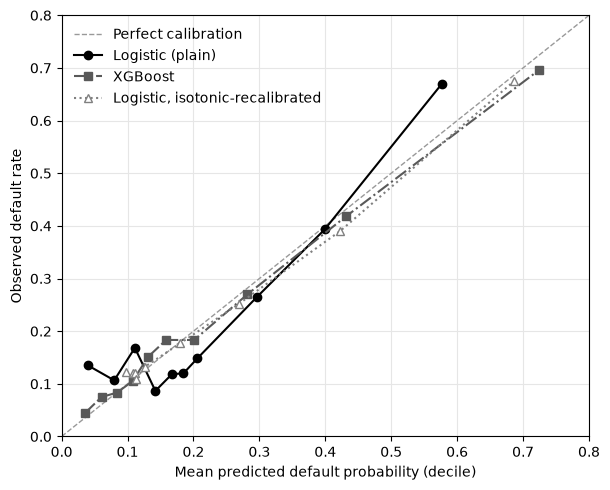

In [13]:
import os
import matplotlib
import matplotlib.pyplot as plt

# Reliability diagram: the full ten-decile version of Table 21.3, plus the recalibrated model.
FIG_REL_LABELS = {'x': "Mean predicted default probability (decile)", 'y': "Observed default rate", 'diag': "Perfect calibration",
                  'lr': "Logistic (plain)", 'xgb': "XGBoost", 'iso': "Logistic, isotonic-recalibrated"}
fig_rel_curves = {}
for fig_key, fig_p in (('lr', proba_plain), ('xgb', models['XGBoost'][0].predict_proba(X_test)[:, 1]),
                       ('iso', proba_calib)):
    fig_bins = pd.qcut(fig_p, 10, duplicates='drop')
    fig_g = pd.DataFrame({'p': fig_p, 'y': y_test.values, 'b': fig_bins}).groupby('b', observed=True).mean()
    fig_rel_curves[fig_key] = (fig_g['p'].values, fig_g['y'].values)
    print(fig_key, "bins:", len(fig_g), " mean predicted:", np.round(fig_g['p'].values, 3))
    print(" " * len(fig_key), "         observed:      ", np.round(fig_g['y'].values, 3))

fig, ax = plt.subplots(figsize=(6.2, 5.0))
ax.plot([0, 0.8], [0, 0.8], color='0.6', linestyle='--', linewidth=1, label=FIG_REL_LABELS['diag'])
ax.plot(*fig_rel_curves['lr'], color='black', marker='o', linestyle='-', label=FIG_REL_LABELS['lr'])
ax.plot(*fig_rel_curves['xgb'], color='0.35', marker='s', linestyle='-.', label=FIG_REL_LABELS['xgb'])
ax.plot(*fig_rel_curves['iso'], color='0.5', marker='^', markerfacecolor='white', linestyle=':',
        label=FIG_REL_LABELS['iso'])
ax.set_xlim(0, 0.8)
ax.set_ylim(0, 0.8)
ax.set_xlabel(FIG_REL_LABELS['x'])
ax.set_ylabel(FIG_REL_LABELS['y'])
ax.legend(loc='upper left', frameon=False)
ax.grid(color='0.9')
plt.tight_layout()
if os.path.isdir("../chapters"):   # the book's figure folder; absent on Colab
    plt.savefig("../chapters/ch21_fig_reliability.pdf", metadata={"CreationDate": None})
else:
    print("Figure not saved: there is no ../chapters folder here (e.g. on Colab).")
plt.show()

## 7. Global explanations: permutation importance and SHAP

Reproduces Table 21.4 of Section 21.2.4: the top features by permutation importance and by mean absolute SHAP value. Look at how the two methods agree on the leaders (`PAY_1`, `max_delinquency`, `avg_utilization`) even though they measure different things.

In [14]:
from sklearn.inspection import permutation_importance
import shap

perm = permutation_importance(xgb_model, X_test, y_test, n_repeats=10, random_state=42, scoring='roc_auc', n_jobs=-1)
imp_df = pd.DataFrame({'feature': feature_cols, 'importance_mean': perm.importances_mean}).sort_values(
    'importance_mean', ascending=False)
print("Top 10 by permutation importance:")
print(imp_df.head(10).to_string(index=False))

explainer = shap.TreeExplainer(xgb_model)
X_test_sample = X_test.iloc[:1000]
shap_values = explainer(X_test_sample)
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)
shap_imp = pd.DataFrame({'feature': feature_cols, 'mean_abs_shap': mean_abs_shap}).sort_values(
    'mean_abs_shap', ascending=False)
print("\nTop 10 by mean |SHAP|:")
print(shap_imp.head(10).to_string(index=False))

Top 10 by permutation importance:
        feature  importance_mean
          PAY_1         0.033747
max_delinquency         0.031750
avg_utilization         0.011762
      BILL_AMT1         0.009448
      LIMIT_BAL         0.005684
       PAY_AMT2         0.004619
     total_bill         0.004442
     total_paid         0.004298
      BILL_AMT5         0.003874
       PAY_AMT3         0.003465



Top 10 by mean |SHAP|:
          feature  mean_abs_shap
  max_delinquency       0.443814
            PAY_1       0.339050
  avg_utilization       0.167244
        BILL_AMT1       0.130010
        LIMIT_BAL       0.118494
         PAY_AMT2       0.101315
         PAY_AMT3       0.082709
         PAY_AMT1       0.073670
       total_paid       0.065664
pay_to_bill_ratio       0.059153


In [15]:
# Section 21.2.4: the top five features by permutation importance and by mean |SHAP| (Table 21.4)
for bv_i in range(5):
    # (the table rounds the six-decimal values the cell above prints)
    book_value(f"Perm{'ABCDE'[bv_i]}", bv_fmt(round(imp_df['importance_mean'].iloc[bv_i], 6), 4))
    book_value(f"Shap{'ABCDE'[bv_i]}", bv_fmt(shap_imp['mean_abs_shap'].iloc[bv_i], 3))

## 8. Individual explanations: a low-risk and a high-risk applicant

Reproduces the two applicants of Section 21.2.4: the low-risk applicant at 13.07% and the high-risk one at 92.2%. Check the completeness property in the last line of each block: the base value $-1.272$ plus the SHAP values gives the model's log-odds output exactly.

In [16]:
idx_low = 0
applicant_low = X_test_sample.iloc[idx_low]
proba_low = xgb_model.predict_proba(X_test_sample.iloc[[idx_low]])[0, 1]
top_low = pd.DataFrame({'feature': feature_cols, 'value': applicant_low.values,
                        'shap': shap_values.values[idx_low]}).sort_values('shap', key=abs, ascending=False)
print("Low-risk applicant, predicted default probability:", round(proba_low, 4))
print(top_low.head(6).to_string(index=False))
print("base value:", explainer.expected_value, " sum shap + base:",
      shap_values.values[idx_low].sum() + explainer.expected_value)

proba_sample = xgb_model.predict_proba(X_test_sample)[:, 1]
idx_high = int(np.argmax(proba_sample))
applicant_high = X_test_sample.iloc[idx_high]
top_high = pd.DataFrame({'feature': feature_cols, 'value': applicant_high.values,
                         'shap': shap_values.values[idx_high]}).sort_values('shap', key=abs, ascending=False)
print("\nHigh-risk applicant, predicted default probability:", round(proba_sample[idx_high], 4))
print(top_high.head(6).to_string(index=False))
print("base value:", explainer.expected_value, " sum shap + base:",
      shap_values.values[idx_high].sum() + explainer.expected_value)

Low-risk applicant, predicted default probability: 0.1307
        feature        value      shap
max_delinquency     0.000000 -0.308778
avg_utilization     0.121113 -0.215403
      LIMIT_BAL 50000.000000  0.174952
          PAY_1    -1.000000 -0.151047
      BILL_AMT1  1540.000000  0.132286
       PAY_AMT1 26060.000000 -0.103337
base value: -1.2719016  sum shap + base: -1.8947152

High-risk applicant, predicted default probability: 0.922
          feature   value     shap
            PAY_1     3.0 1.008909
  max_delinquency     7.0 0.920935
        LIMIT_BAL 10000.0 0.303218
        BILL_AMT1  2300.0 0.233407
            PAY_6     7.0 0.158055
pay_to_bill_ratio     0.0 0.151419
base value: -1.2719016  sum shap + base: 2.4697156


In [17]:
# Section 21.2.4: the low-risk and high-risk applicants' SHAP decompositions
bv_base = float(explainer.expected_value)
book_value("ShapBase", bv_fmt(bv_base, 3))
book_value("LowPDPct", bv_fmt(100 * proba_low, 2))
book_value("LowLogOdds", bv_fmt(bv_base + shap_values.values[idx_low].sum(), 3))
for bv_i in range(4):
    book_value(f"LowShap{'ABCD'[bv_i]}", bv_fmt(top_low['shap'].iloc[bv_i], 3, sign=True))
book_value("HighPDPct", bv_fmt(100 * proba_sample[idx_high], 1))
book_value("HighPDPctTwo", bv_fmt(100 * proba_sample[idx_high], 2))
book_value("HighLogOdds", bv_fmt(bv_base + shap_values.values[idx_high].sum(), 3))
for bv_i in range(6):
    book_value(f"HighShap{'ABCDEF'[bv_i]}", bv_fmt(top_high['shap'].iloc[bv_i], 3, sign=True))

### 8b. SHAP waterfall for the low-risk applicant (figure for the chapter)

Draws Figure 21.2, the low-risk applicant's waterfall: the seven largest contributions, the remaining 18 features combined ($-0.247$), and the output of $-1.895$.

base value -1.272
  max_delinquency = 0              -0.309
  avg_utilization = 0.121          -0.215
  LIMIT_BAL = 50,000               +0.175
  PAY_1 = -1                       -0.151
  BILL_AMT1 = 1,540                +0.132
  PAY_AMT1 = 26,060                -0.103
  PAY_AMT2 = 0                     +0.096
  18 other features                -0.247
output (log-odds) -1.895  -> probability 0.1307


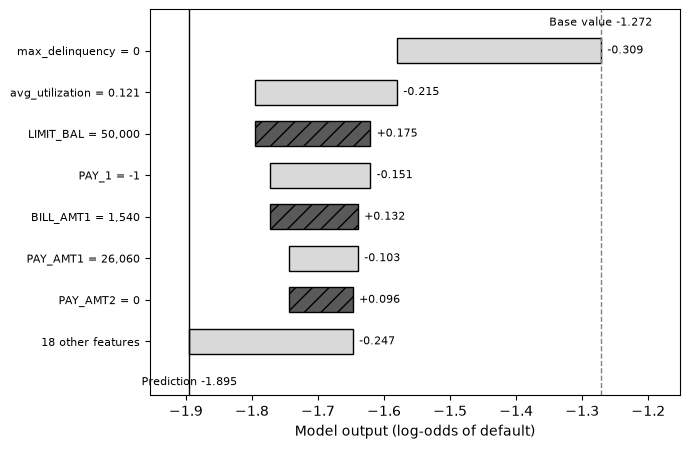

In [18]:
import os
import matplotlib
import matplotlib.pyplot as plt

# SHAP waterfall for the low-risk applicant: base value, the seven largest contributions,
# the remaining features combined, and the model's log-odds output.
FIG_WF_LABELS = {'x': "Model output (log-odds of default)", 'base': "Base value", 'out': "Prediction", 'other': "{n} other features"}
fig_wf_base = float(explainer.expected_value)
fig_wf_sv = shap_values.values[idx_low]
fig_wf_order = np.argsort(-np.abs(fig_wf_sv))
fig_wf_top = fig_wf_order[:7]
fig_wf_rest = fig_wf_sv[fig_wf_order[7:]].sum()
fig_wf_names = []
for j in fig_wf_top:
    fig_v = applicant_low.values[j]
    fig_vs = f"{fig_v:.3f}" if feature_cols[j] == 'avg_utilization' else f"{fig_v:,.0f}"
    fig_wf_names.append(f"{feature_cols[j]} = {fig_vs}")
fig_wf_names.append(FIG_WF_LABELS['other'].format(n=len(feature_cols) - 7))
fig_wf_vals = list(fig_wf_sv[fig_wf_top]) + [fig_wf_rest]
fig_wf_out = fig_wf_base + sum(fig_wf_vals)
print(f"base value {fig_wf_base:.3f}")
for fig_n, fig_s in zip(fig_wf_names, fig_wf_vals):
    print(f"  {fig_n:<32} {fig_s:+.3f}")
print(f"output (log-odds) {fig_wf_out:.3f}  -> probability {1 / (1 + np.exp(-fig_wf_out)):.4f}")

fig, ax = plt.subplots(figsize=(7.0, 4.6))
fig_left = fig_wf_base
fig_rows = len(fig_wf_vals)
for i, (fig_n, fig_s) in enumerate(zip(fig_wf_names, fig_wf_vals)):
    fig_y = fig_rows - i
    if fig_s >= 0:
        ax.barh(fig_y, fig_s, left=fig_left, color='0.35', edgecolor='black', hatch='//', height=0.6)
    else:
        ax.barh(fig_y, fig_s, left=fig_left, color='0.85', edgecolor='black', height=0.6)
    ax.text(max(fig_left, fig_left + fig_s) + 0.01, fig_y, f"{fig_s:+.3f}", va='center', fontsize=8)
    fig_left += fig_s
ax.axvline(fig_wf_base, color='0.5', linestyle='--', linewidth=1)
ax.axvline(fig_wf_out, color='black', linestyle='-', linewidth=1)
ax.set_yticks(range(fig_rows, 0, -1))
ax.set_yticklabels(fig_wf_names, fontsize=8)
ax.set_xlabel(FIG_WF_LABELS['x'])
ax.set_ylim(-0.3, fig_rows + 1.0)
ax.set_xlim(min(fig_wf_out, fig_left) - 0.06, fig_wf_base + 0.12)
ax.text(fig_wf_base, fig_rows + 0.6, f"{FIG_WF_LABELS['base']} {fig_wf_base:.3f}", ha='center', fontsize=8)
ax.text(fig_wf_out, -0.05, f"{FIG_WF_LABELS['out']} {fig_wf_out:.3f}", ha='center', fontsize=8)
plt.tight_layout()
if os.path.isdir("../chapters"):   # the book's figure folder; absent on Colab
    plt.savefig("../chapters/ch21_fig_shap_waterfall.pdf", metadata={"CreationDate": None})
else:
    print("Figure not saved: there is no ../chapters folder here (e.g. on Colab).")
plt.show()

In [19]:
# Figure 21.2: the waterfall's "other features" bar
book_value("LowShapRest", bv_fmt(fig_wf_rest, 3))

### A worked example: from predicted probability to a provisioning number (EL = PD x LGD x EAD)

Reproduces Worked Example 21.1: expected loss $\text{PD}\times\text{LGD}\times\text{EAD}$ for the two applicants. Look at how the smaller credit limit offsets the high-risk applicant's seven-fold PD, leaving an expected-loss ratio of only 1.41.

In [20]:
LGD = 0.60  # Chapter 9's illustrative loss-given-default assumption, reused here for an unsecured card balance

ead_low = applicant_low["LIMIT_BAL"]
ead_high = applicant_high["LIMIT_BAL"]

el_low = proba_low * LGD * ead_low
el_high = proba_sample[idx_high] * LGD * ead_high

# LIMIT_BAL, and hence EAD and EL, are in New Taiwan dollars (NT$)
print(f"Low-risk applicant:  PD={proba_low:.7f}  EAD=NT${ead_low:,.0f}  LGD={LGD}  ->  EL=NT${el_low:,.2f}")
print(f"High-risk applicant: PD={proba_sample[idx_high]:.7f}  EAD=NT${ead_high:,.0f}  LGD={LGD}  ->  EL=NT${el_high:,.2f}")
print(f"\nEL ratio (high/low): {el_high/el_low:.2f}")
print(f"PD ratio (high/low): {proba_sample[idx_high]/proba_low:.2f}")

Low-risk applicant:  PD=0.1307077  EAD=NT$50,000  LGD=0.6  ->  EL=NT$3,921.23
High-risk applicant: PD=0.9219913  EAD=NT$10,000  LGD=0.6  ->  EL=NT$5,531.95

EL ratio (high/low): 1.41
PD ratio (high/low): 7.05


In [21]:
# Worked Example 21.1: expected loss for the two applicants
book_value("LowPDPctFive", bv_fmt(100 * proba_low, 5))
book_value("LowPDSeven", bv_fmt(proba_low, 7))
book_value("HighPDPctFive", bv_fmt(100 * proba_sample[idx_high], 5))
book_value("HighPDSeven", bv_fmt(proba_sample[idx_high], 7))
book_value("ELLow", bv_fmt(el_low, 2, sep="{,}"))
book_value("ELHigh", bv_fmt(el_high, 2, sep="{,}"))
book_value("ELRatio", bv_fmt(el_high / el_low, 2))
book_value("PDRatio", bv_fmt(proba_sample[idx_high] / proba_low, 2))

## 9. Cost-sensitive threshold selection

Reproduces Table 21.5 and the operating point of Section 21.2.5. Look at the grid minimum at $t=0.10$ (\$209,750) against \$438,900 at the naive 0.5, at the analytic threshold $0.091$, and at what the strict cutoff implies: only 31.6% of accounts approved.

In [22]:
from sklearn.metrics import confusion_matrix

proba_xgb = xgb_model.predict_proba(X_test)[:, 1]
cost_fn, cost_fp = 500, 50
thresholds = np.arange(0.05, 0.61, 0.01)
cost_table = []
for t in thresholds:
    pred_t = (proba_xgb >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_t).ravel()
    cost_table.append((t, fn, fp, fn * cost_fn + fp * cost_fp))
cost_df = pd.DataFrame(cost_table, columns=['threshold', 'fn', 'fp', 'total_cost'])
best_row = cost_df.loc[cost_df['total_cost'].idxmin()]
show_t = sorted(set([0.05, 0.20, 0.35, 0.50, 0.60, round(best_row['threshold'], 2)]))
print(cost_df[cost_df['threshold'].round(2).isin(show_t)].round(2).to_string(index=False))
print("\ncost-minimizing threshold:", best_row['threshold'], " total cost:", best_row['total_cost'])
print("cost at naive 0.5 threshold:", cost_df.loc[np.isclose(cost_df['threshold'], 0.5), 'total_cost'].values[0])
best_t = best_row['threshold']
t_star = cost_fp / (cost_fp + cost_fn)   # deny when p*cost_fn > (1-p)*cost_fp
pred_star = (proba_xgb >= t_star).astype(int)
tn_s, fp_s, fn_s, tp_s = confusion_matrix(y_test, pred_star).ravel()
print(f"analytic threshold c_FP/(c_FP+c_FN) = {t_star:.4f}, cost there: {fn_s * cost_fn + fp_s * cost_fp}")
print(f"approval rate at the cost-minimizing threshold: {(proba_xgb < best_t).mean():.4f}")
print(f"approval rate at the naive 0.5 threshold: {(proba_xgb < 0.5).mean():.4f}")
nd = (y_test.values == 0)
print(f"share of non-defaulters denied at the cost-minimizing threshold: {(proba_xgb[nd] >= best_t).mean():.4f}")


 threshold  fn   fp  total_cost
      0.05  29 4071      218050
      0.10 129 2905      209750
      0.20 450 1218      285900
      0.35 667  510      359000
      0.50 854  238      438900
      0.60 918  179      467950

cost-minimizing threshold: 0.1  total cost: 209750.0
cost at naive 0.5 threshold: 438900
analytic threshold c_FP/(c_FP+c_FN) = 0.0909, cost there: 214100
approval rate at the cost-minimizing threshold: 0.3162
approval rate at the naive 0.5 threshold: 0.8815
share of non-defaulters denied at the cost-minimizing threshold: 0.6217


In [23]:
# Section 21.2.5: the cost table (Table 21.5) and the operating point
# (rates are rounded to the four decimals the cell above prints, as the text does)
for bv_t, bv_tag in ((0.05, 'A'), (0.10, 'B'), (0.20, 'C'), (0.35, 'D'), (0.50, 'E'), (0.60, 'F')):
    bv_r = cost_df.loc[np.isclose(cost_df['threshold'], bv_t)].iloc[0]
    book_value(f"Cost{bv_tag}FN", f"{int(bv_r['fn'])}")
    book_value(f"Cost{bv_tag}FP", bv_fmt(bv_r['fp'], 0, sep="{,}"))
    book_value(f"Cost{bv_tag}Total", bv_fmt(bv_r['total_cost'], 0, sep="{,}"))
    book_value(f"Cost{bv_tag}TotalComma", bv_fmt(bv_r['total_cost'], 0, sep=","))
book_value("CostAtTStarComma", bv_fmt(fn_s * cost_fn + fp_s * cost_fp, 0, sep=","))
book_value("ApproveBestPct", bv_fmt(100 * round((proba_xgb < best_t).mean(), 4), 1))
book_value("ApproveNaivePct", bv_fmt(100 * round((proba_xgb < 0.5).mean(), 4), 1))
book_value("GoodDeniedPct", bv_fmt(100 * round((proba_xgb[nd] >= best_t).mean(), 4), 1))

### 9b. Cost against threshold (figure for the chapter)

Draws Figure 21.3, the total cost at every threshold on the 0.01 grid. Notice how flat the curve is around its minimum and how steeply it climbs toward the naive threshold.

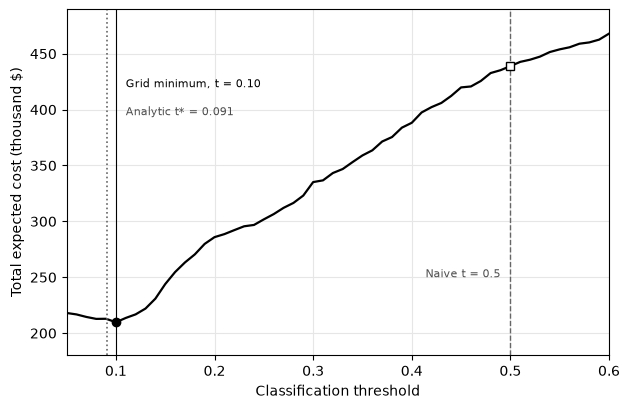

cost at t = 0.05, 0.10, 0.50, 0.60 (thousand $): [218.05, 209.75, 438.9, 467.95]


In [24]:
import os
import matplotlib
import matplotlib.pyplot as plt

# Total expected cost against the threshold, over the full 0.05-0.60 grid behind Table 21.5.
FIG_COST_LABELS = {'x': "Classification threshold", 'y': "Total expected cost (thousand $)", 'min': "Grid minimum, t = 0.10",
                   'star': "Analytic t* = 0.091", 'naive': "Naive t = 0.5"}
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(cost_df['threshold'], cost_df['total_cost'] / 1000, color='black', linewidth=1.6)
ax.axvline(best_t, color='black', linestyle='-', linewidth=0.8)
ax.axvline(t_star, color='0.4', linestyle=':', linewidth=1.2)
ax.axvline(0.5, color='0.4', linestyle='--', linewidth=1.0)
ax.plot([best_t], [best_row['total_cost'] / 1000], 'o', color='black')
ax.plot([0.5], [cost_df.loc[np.isclose(cost_df['threshold'], 0.5), 'total_cost'].values[0] / 1000],
        's', color='black', markerfacecolor='white')
ax.text(best_t + 0.01, 420, FIG_COST_LABELS['min'], fontsize=8)
ax.text(best_t + 0.01, 395, FIG_COST_LABELS['star'], fontsize=8, color='0.3')
ax.text(0.5 - 0.01, 250, FIG_COST_LABELS['naive'], fontsize=8, ha='right', color='0.3')
ax.set_xlabel(FIG_COST_LABELS['x'])
ax.set_ylabel(FIG_COST_LABELS['y'])
ax.set_xlim(0.05, 0.60)
ax.set_ylim(180, 490)
ax.grid(color='0.9')
plt.tight_layout()
if os.path.isdir("../chapters"):   # the book's figure folder; absent on Colab
    plt.savefig("../chapters/ch21_fig_cost_threshold.pdf", metadata={"CreationDate": None})
else:
    print("Figure not saved: there is no ../chapters folder here (e.g. on Colab).")
plt.show()
print("cost at t = 0.05, 0.10, 0.50, 0.60 (thousand $):",
      [round(float(cost_df.loc[np.isclose(cost_df['threshold'], t), 'total_cost'].values[0]) / 1000, 2)
       for t in (0.05, 0.10, 0.50, 0.60)])

### Experiment

The cost-minimizing threshold moves with the ratio of the two costs, $c_{FP}/(c_{FP}+c_{FN})$. Change the two costs on the commented lines and re-run the cell. With the defaults (\$500 for approving an account that defaults, \$50 for denying one that would have repaid) it reproduces Section 21.2.5: the grid minimum at $t=0.10$ with a total cost of \$209,750, next to the analytic $t^*=0.091$.

In [25]:
EXP21_LBL = {'now': 'c_FN = ${}, c_FP = ${}: grid minimum t = {:.2f}, total cost ${:,}; analytic t* = {:.3f}; approval rate {:.1%}', 'book': 'Book value (Section 21.2.5, $500 and $50): t = 0.10, total cost $209,750; analytic t* = 0.091; approval rate 31.6%'}
exp21_cost_fn = 500   # cost of approving an account that then defaults; try 250 or 750
exp21_cost_fp = 50    # cost of denying an account that would have repaid; try 100
exp21_p = xgb_model.predict_proba(X_test)[:, 1]
exp21_y = y_test.values
exp21_grid = np.arange(0.05, 0.61, 0.01)
exp21_cost = np.array([exp21_cost_fn * int(((exp21_p < t) & (exp21_y == 1)).sum())
                       + exp21_cost_fp * int(((exp21_p >= t) & (exp21_y == 0)).sum()) for t in exp21_grid])
exp21_i = int(np.argmin(exp21_cost))
print(EXP21_LBL["now"].format(exp21_cost_fn, exp21_cost_fp, exp21_grid[exp21_i], exp21_cost[exp21_i],
                              exp21_cost_fp / (exp21_cost_fp + exp21_cost_fn), (exp21_p < exp21_grid[exp21_i]).mean()))
print(EXP21_LBL["book"])

c_FN = $500, c_FP = $50: grid minimum t = 0.10, total cost $209,750; analytic t* = 0.091; approval rate 31.6%
Book value (Section 21.2.5, $500 and $50): t = 0.10, total cost $209,750; analytic t* = 0.091; approval rate 31.6%


## 10. Fairness audit by sex

Reproduces Table 21.6 of Section 21.2.6 and the contrast model. Look at the adverse impact ratio of 0.960, at the higher false-negative rate of the group with the higher approval rate, and at the second cell: refitting with `SEX`, `MARRIAGE` and `AGE` as inputs lowers the ratio to 0.843 at almost no gain in ROC-AUC.

In [26]:
pred_final = (proba_xgb >= best_t).astype(int)
audit_df = pd.DataFrame({'sex': sex_test.values, 'actual': y_test.values, 'pred_default': pred_final, 'proba': proba_xgb})

results = {}
for s, label in [(1, 'Male'), (2, 'Female')]:
    sub = audit_df[audit_df['sex'] == s]
    approval_rate = (sub['pred_default'] == 0).mean()
    defaulters = sub[sub['actual'] == 1]
    fnr = defaulters['pred_default'].eq(0).mean()
    non_defaulters = sub[sub['actual'] == 0]
    fpr = non_defaulters['pred_default'].eq(1).mean()
    results[label] = approval_rate
    print(f"{label}: n={len(sub)} default_rate={sub['actual'].mean():.4f} approval_rate={approval_rate:.4f} FNR={fnr:.4f} FPR={fpr:.4f}")

air = min(results.values()) / max(results.values())
print("\nadverse impact ratio:", round(air, 4))

Male: n=2402 default_rate=0.2336 approval_rate=0.3085 FNR=0.0891 FPR=0.6247
Female: n=3598 default_rate=0.2129 approval_rate=0.3213 FNR=0.1031 FPR=0.6197

adverse impact ratio: 0.9602


In [27]:
# Section 21.2.6: the fairness audit by sex (Table 21.6)
# (rates are rounded to the four decimals the cell above prints, as the text does)
for bv_s, bv_tag in ((1, 'Male'), (2, 'Female')):
    bv_sub = audit_df[audit_df['sex'] == bv_s]
    book_value(f"Fair{bv_tag}ApprovePct", bv_fmt(100 * round((bv_sub['pred_default'] == 0).mean(), 4), 1))
    book_value(f"Fair{bv_tag}ApprovePctTwo", bv_fmt(100 * (bv_sub['pred_default'] == 0).mean(), 2))
    book_value(f"Fair{bv_tag}FNRPct", bv_fmt(100 * round(bv_sub.loc[bv_sub['actual'] == 1, 'pred_default'].eq(0).mean(), 4), 1))
    book_value(f"Fair{bv_tag}FPRPct", bv_fmt(100 * round(bv_sub.loc[bv_sub['actual'] == 0, 'pred_default'].eq(1).mean(), 4), 1))
book_value("FairAIR", bv_fmt(air, 3))

In [28]:
# For contrast only, not a deployable model: the same XGBoost configuration refit WITH SEX, MARRIAGE and AGE
# as inputs, audited at the same threshold, to measure how much leaving them out actually changed.
demo_cols = feature_cols + ['SEX', 'MARRIAGE', 'AGE']
demo_Xtr = df.loc[X_train.index, demo_cols]
demo_Xte = df.loc[X_test.index, demo_cols]
demo_model = xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                               colsample_bytree=0.8, eval_metric='logloss', random_state=42, n_jobs=-1)
demo_model.fit(demo_Xtr, y_train)
demo_proba = demo_model.predict_proba(demo_Xte)[:, 1]
print("with-demographics test ROC-AUC:", round(roc_auc_score(y_test, demo_proba), 4))
demo_rates = {}
for s, label in [(1, 'Male'), (2, 'Female')]:
    mask = (sex_test.values == s)
    demo_rates[label] = (demo_proba[mask] < best_t).mean()
    print(f"{label}: approval_rate={demo_rates[label]:.4f}")
print("with-demographics adverse impact ratio:", round(min(demo_rates.values()) / max(demo_rates.values()), 4))


with-demographics test ROC-AUC: 0.7787
Male: approval_rate=0.2860
Female: approval_rate=0.3394
with-demographics adverse impact ratio: 0.8428


In [29]:
# Section 21.2.6: the contrast model refit with the demographic attributes
# (rates are rounded to the four decimals the cell above prints, as the text does)
book_value("DemoAUC", bv_fmt(roc_auc_score(y_test, demo_proba), 3))
book_value("DemoMaleApprovePct", bv_fmt(100 * round(demo_rates['Male'], 4), 1))
book_value("DemoFemaleApprovePct", bv_fmt(100 * round(demo_rates['Female'], 4), 1))
book_value("DemoAIR", bv_fmt(min(demo_rates.values()) / max(demo_rates.values()), 3))

## 11. Hyperparameter tuning via cross-validation

Reproduces Section 21.3.3: a randomized search over 30 configurations with five-fold cross-validation on the training set. Look at how little it buys: test ROC-AUC 0.781 against the untuned 0.778, and the gap between the cross-validated 0.786 and the test score.

In [30]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

param_dist = {
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'n_estimators': [100, 200, 300, 500],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],
}
# one thread per model and a capped number of parallel fits, rather than n_jobs=-1 at both levels,
# which oversubscribes the cores (every parallel fit would itself spawn one thread per core)
base_xgb = xgb.XGBClassifier(eval_metric='logloss', random_state=42, n_jobs=1)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = RandomizedSearchCV(base_xgb, param_distributions=param_dist, n_iter=30, scoring='roc_auc',
                             cv=cv, random_state=42, n_jobs=min(4, os.cpu_count() or 1))
search.fit(X_train, y_train)
print("best params:", search.best_params_)
print("best CV ROC-AUC:", round(search.best_score_, 4))

tuned_model = search.best_estimator_
proba_tuned = tuned_model.predict_proba(X_test)[:, 1]
print("tuned test ROC-AUC:", round(roc_auc_score(y_test, proba_tuned), 4))
print("tuned test PR-AUC:", round(average_precision_score(y_test, proba_tuned), 4))
print("tuned test Brier:", round(brier_score_loss(y_test, proba_tuned), 4))
print("untuned test ROC-AUC (for comparison):", round(roc_auc_score(y_test, proba_xgb), 4))

best params: {'subsample': 1.0, 'n_estimators': 100, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.6}
best CV ROC-AUC: 0.786
tuned test ROC-AUC: 0.7807
tuned test PR-AUC: 0.5539
tuned test Brier: 0.1349
untuned test ROC-AUC (for comparison): 0.778


In [31]:
# Section 21.3.3: the hyperparameter search
book_value("TunedCVAUC", bv_fmt(search.best_score_, 3))
book_value("TunedAUC", bv_fmt(roc_auc_score(y_test, proba_tuned), 3))
book_value("TunedPRAUC", bv_fmt(average_precision_score(y_test, proba_tuned), 3))
book_value("TunedBrier", bv_fmt(brier_score_loss(y_test, proba_tuned), 3))

## 12. Intersectional fairness check: sex crossed with age group

Reproduces Table 21.7 of Section 21.3.4. Look at the intersectional adverse impact ratio of 0.713, a four-fifths-rule failure that the sex-only audit (0.960) gave no hint of, and at the median credit limits, the most obvious proxy.

In [32]:
audit_df['age_group'] = np.where(age_test.values < 30, 'Under 30', '30 and over')
audit_df['limit'] = X_test['LIMIT_BAL'].values

intersect_results = {}
for s, slabel in [(1, 'Male'), (2, 'Female')]:
    for ag in ['Under 30', '30 and over']:
        sub = audit_df[(audit_df['sex'] == s) & (audit_df['age_group'] == ag)]
        ar = (sub['pred_default'] == 0).mean()
        defaulters = sub[sub['actual'] == 1]
        fnr = defaulters['pred_default'].eq(0).mean() if len(defaulters) > 0 else float('nan')
        intersect_results[(slabel, ag)] = ar
        print(f"{slabel}, {ag}: n={len(sub)} approval_rate={ar:.4f} FNR={fnr:.4f} median_LIMIT_BAL={sub['limit'].median():,.0f}")

air_intersect = min(intersect_results.values()) / max(intersect_results.values())
print("\nintersectional adverse impact ratio:", round(air_intersect, 4))

Male, Under 30: n=669 approval_rate=0.2392 FNR=0.0467 median_LIMIT_BAL=80,000
Male, 30 and over: n=1733 approval_rate=0.3353 FNR=0.1046 median_LIMIT_BAL=150,000
Female, Under 30: n=1243 approval_rate=0.3001 FNR=0.1011 median_LIMIT_BAL=100,000
Female, 30 and over: n=2355 approval_rate=0.3325 FNR=0.1043 median_LIMIT_BAL=170,000

intersectional adverse impact ratio: 0.7134


In [33]:
# Section 21.3.4: the intersectional audit (Table 21.7)
# (rates are rounded to the four decimals the cell above prints, as the text does)
for (bv_sl, bv_ag), bv_ar in intersect_results.items():
    bv_tag = bv_sl + ('Young' if bv_ag == 'Under 30' else 'Older')
    bv_sub = audit_df[(audit_df['sex'] == (1 if bv_sl == 'Male' else 2)) & (audit_df['age_group'] == bv_ag)]
    book_value(f"Inter{bv_tag}ApprovePct", bv_fmt(100 * round(bv_ar, 4), 1))
    book_value(f"Inter{bv_tag}ApprovePctTwo", bv_fmt(100 * bv_ar, 2))
    book_value(f"Inter{bv_tag}FNRPct", bv_fmt(100 * round(bv_sub.loc[bv_sub['actual'] == 1, 'pred_default'].eq(0).mean(), 4), 1))
book_value("InterAIR", bv_fmt(air_intersect, 3))
book_value("InterFemaleRatio", bv_fmt(intersect_results[('Female', 'Under 30')] / intersect_results[('Female', '30 and over')], 2))

## 13. Stage 9, deploy and monitor: training-serving skew on one applicant

Reproduces the training-serving skew example of Stage 9 in Section 21.3.5. Look at how one feature computed two ways turns a decline (PD 34.7%) into an approval (21.4%) with no error raised anywhere.

In [34]:
# Stage 9 (deploy and monitor): training-serving skew on one applicant.
# The same feature, "three-day average balance", resolved by the warehouse (which already holds
# the decision day) and by the live service (which does not), fed to a one-feature scorecard.
import numpy as np
sk_balances = {'t-3': 1000.0, 't-2': 1000.0, 't-1': 1000.0, 't': 200.0}
sk_train_x = np.mean([sk_balances['t-2'], sk_balances['t-1'], sk_balances['t']])
sk_serve_x = np.mean([sk_balances['t-3'], sk_balances['t-2'], sk_balances['t-1']])
sk_cutoff = 0.30


def sk_pd(x):
    return 1 / (1 + np.exp(-(1.2 - 0.0025 * x)))


for sk_name, sk_x in (("training (warehouse)", sk_train_x), ("serving (live feed)", sk_serve_x)):
    sk_p = sk_pd(sk_x)
    print(f"{sk_name:<22} feature = {sk_x:8.2f}  PD = {sk_p:.4f}  decision = "
          f"{'decline' if sk_p > sk_cutoff else 'approve'}")
sk_gap = sk_pd(sk_train_x) - sk_pd(sk_serve_x)
print(f"served PD understates the trained PD by {100 * sk_gap:.1f} points, "
      f"{100 * sk_gap / sk_pd(sk_train_x):.0f}% of the correct figure")

training (warehouse)   feature =   733.33  PD = 0.3468  decision = decline
serving (live feed)    feature =  1000.00  PD = 0.2142  decision = approve
served PD understates the trained PD by 13.3 points, 38% of the correct figure


In [35]:
# Write the collected values as LaTeX macros for the chapter (see the first book_value cell)
import os
if os.path.isdir("../chapters"):
    os.makedirs("../chapters/values", exist_ok=True)
    with open("../chapters/values/ch21.tex", "w", encoding="utf-8", newline="\n") as _vf:
        _vf.write("% Generated by the Chapter 21 companion notebook. Do not edit by hand: re-run the notebook.\n")
        for _vk, _vv in BOOK_VALUES.items():
            _vf.write(f"\\newcommand{{\\vChTwentyOne{_vk}}}{{{_vv}}}\n")
    print(f"wrote {len(BOOK_VALUES)} values to ../chapters/values/ch21.tex")
else:
    print("Values file not written: there is no ../chapters folder here (e.g. on Colab).")

wrote 239 values to ../chapters/values/ch21.tex
